In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## reliability-diagram

**Figure 1: Confidence histograms (top) and reliability diagrams (bottom) for a 5-layer LeNet (left) and a 110-layer ResNet (right) on CIFAR-100.** In the reliability diagrams, the Gap bars span from each bin's accuracy to its average confidence and the dashed diagonal marks perfect calibration. The ResNet is more accurate (error 30.6 vs. 44.9) but overconfident, with an average confidence of 0.884 against an accuracy of 0.705, whereas LeNet's average confidence (0.500) nearly matches its accuracy (0.541).

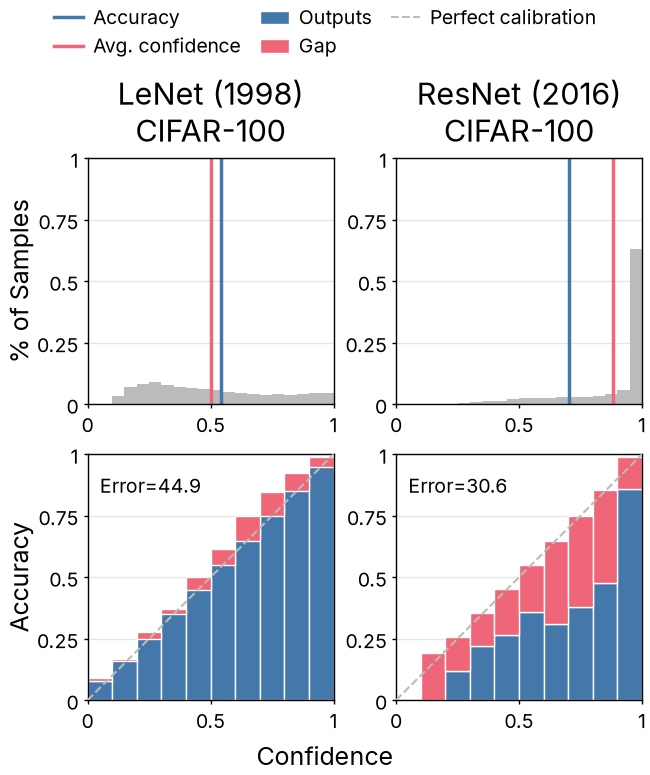

In [2]:
with open("../reliability-diagram.json") as f:
    data = json.load(f)

reliability_edges = np.array(data["reliability_bin_edges"])
histogram_edges = np.array(data["histogram_bin_edges"])

fig, axes = plt.subplots(2, 2, figsize=(3.25, 3.5), sharex=True, sharey=True)
for col, name in enumerate(["lenet", "resnet"]):
    model = data["models"][name]
    hist_ax, rel_ax = axes[0, col], axes[1, col]

    hist_ax.hist(histogram_edges[:-1], bins=histogram_edges, weights=model["fraction_of_samples_per_bin"],
                 color=colors["neutral"], linewidth=0)
    hist_ax.axvline(model["accuracy_line"], color=colors["series-1"], label="Accuracy")
    hist_ax.axvline(model["avg_confidence_line"], color=colors["series-2"], label="Avg. confidence")
    hist_ax.grid(axis="x", visible=False)
    hist_ax.set_title(f"{model['label']}\nCIFAR-100")

    accuracy = np.array(model["accuracy_per_bin"])
    confidence = np.array(model["avg_confidence_per_bin"])
    width = reliability_edges[1] - reliability_edges[0]
    rel_ax.bar(reliability_edges[:-1], accuracy, width, align="edge", color=colors["series-1"],
               edgecolor="white", linewidth=0.5, label="Outputs")
    rel_ax.bar(reliability_edges[:-1], np.abs(confidence - accuracy), width, bottom=np.minimum(accuracy, confidence),
               align="edge", color=colors["series-2"], edgecolor="white", linewidth=0.5, label="Gap")
    rel_ax.plot([0, 1], [0, 1], linestyle="--", linewidth=0.75, color=colors["neutral"], zorder=3,
                label="Perfect calibration")
    rel_ax.text(0.05, 0.92, f"Error={model['error_percent']}", transform=rel_ax.transAxes,
                ha="left", va="top")
    rel_ax.grid(axis="x", visible=False)

for ax in axes.flat:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.5, 1], labels=["0", "0.5", "1"])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1], labels=["0", "0.25", "0.5", "0.75", "1"])
    ax.tick_params(labelleft=True, labelbottom=True)
axes[0, 0].set_ylabel("% of Samples")
axes[1, 0].set_ylabel("Accuracy")
fig.supxlabel("Confidence")

hist_handles, hist_labels = axes[0, 0].get_legend_handles_labels()
rel_handles, rel_labels = axes[1, 0].get_legend_handles_labels()
order = [rel_labels.index(name) for name in ["Outputs", "Gap", "Perfect calibration"]]
fig.legend(hist_handles + [rel_handles[i] for i in order], hist_labels + [rel_labels[i] for i in order], loc="outside upper center", ncol=3, frameon=False, borderaxespad=0)

fit_height(fig, axes, aspect=1.0)
fig.savefig("reliability-diagram.pdf")
fig.savefig("reliability-diagram.png")
plt.show()